# 07 — Pelatihan semua model (T13, T25, T28–T34)

Satu tempat untuk melatih: **baseline, RF, XGBoost, LSTM, dan ablasi 8 konfigurasi**. Evaluasi ada di `08_evaluate`, XAI di `09_xai`.

| Bagian | Isi |
|---|---|
| 1 | TK2: bekukan set fitur (cek konsisten dengan pembekuan sebelumnya) |
| 2 | Baseline: klimatologi, persistence, GFS mentah, MOS |
| 3 | Hyperparameter: **pakai `models/best_params.json` bila ada** (tidak tuning ulang setelah uji dilihat); tuning hanya bila belum ada |
| 4 | Latih final RF & XGB (target k_c + fitur fisika) → simpan model |
| 5 | Ablasi 2×2×2 (XGB) |
| 6 | LSTM encoder–decoder → simpan model & normalisasi |
| 7 | Simpan semua prediksi (+ prediksi mentah sebelum clipping) + cek identik dengan run sebelumnya |

Keputusan: latih 2016–18, pilih di 2019, **tanpa refit** (#9).

## 0. Setup

In [9]:
import hashlib, json, shutil, sys, time
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt, yaml

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
import importlib, evaluate as E, models as M, lstm as L, clearsky
for mod in (clearsky, E, M, L): importlib.reload(mod)
from utils import set_seed

CFG = yaml.safe_load(open(ROOT / "configs" / "config.yaml"))
PROC, RES, FIG, MOD = ROOT / "data/processed", ROOT / "results", ROOT / "figures", ROOT / "models"
MOD.mkdir(exist_ok=True)
SEED = set_seed(CFG["seed"]); KZ = CFG["physics"]["k_max_by_zenith"]
USE_SAVED_PARAMS = True
N_TRIALS = {"xgb": 30, "rf": 15, "lstm": 15}

df = pd.read_parquet(PROC / "features_all.parquet")
hourly = pd.read_parquet(ROOT / "data/interim/nsrdb_hourly_kc.parquet")
TRAIN = (df["split"] == "train") & df["is_day"]
VALM = E.masks(df)["valid"] & (df["split"] == "val")
print(f"{len(df):,} baris | latih (siang) {int(TRAIN.sum()):,} | val (valid) {int(VALM.sum()):,}")

43,848 baris | latih (siang) 12,496 | val (valid) 3,289


## 1. TK2 — set fitur beku

In [10]:
FEATS = M.feature_list(df, with_phys=True)
h = hashlib.md5(open(PROC / "features_all.parquet", "rb").read()).hexdigest()
ff = RES / "feature_freeze.json"
if ff.exists():
    old = json.loads(ff.read_text())
    assert old["fitur"] == FEATS, "Daftar fitur berbeda dari pembekuan TK2 sebelumnya!"
    print("✓ Fitur sama dengan pembekuan", old["tanggal"], "| md5 data", "sama" if old["md5_features_all"] == h else "BERBEDA ⚠")
else:
    _ = ff.write_text(json.dumps({"tanggal": str(pd.Timestamp.today().date()), "fitur": FEATS, "n_fitur": len(FEATS),
                                  "fitur_fisika": [c for c in M.PHYS if c in df], "md5_features_all": h}, indent=2))
    print("TK2 dibekukan:", len(FEATS), "fitur")

TK2 dibekukan: 31 fitur


## 2. Baseline

In [11]:
B = M.baselines(df, TRAIN)
print(list(B))

['pred_clim', 'pred_persist', 'pred_gfs_raw', 'pred_mos']


## 3. Hyperparameter (pakai yang tersimpan; tuning hanya bila belum ada)

In [12]:
bp = MOD / "best_params.json"
BEST = json.loads(bp.read_text()) if bp.exists() else {}
need = [k for k in ("xgb", "rf", "lstm") if not (USE_SAVED_PARAMS and k in BEST)]
print("Parameter tersimpan:", [k for k in BEST], "| perlu tuning:", need or "—")
for kind in [k for k in need if k in ("xgb", "rf")]:
    t0 = time.time()
    BEST[kind], trials = M.tune(kind, df, FEATS, TRAIN, VALM, "kc", KZ, SEED, N_TRIALS[kind])
    trials.to_csv(RES / f"optuna_{kind}.csv", index=False)
    print(f"{kind}: tuning {time.time() - t0:.0f} dtk")
_ = bp.write_text(json.dumps(BEST, indent=2))

Parameter tersimpan: ['xgb', 'rf', 'lstm'] | perlu tuning: —


## 4. RF & XGBoost final (target k_c + fitur fisika)

In [13]:
P = df[["target_day", "target_hour_wib", "target_time_utc", "split", "y_ghi", "y_kc", "ghi_cs", "zenith",
        "is_day", "eval_valid"]].copy()
P = P.join(B)
for kind in ("xgb", "rf"):
    m = M.fit_model(kind, BEST[kind], df, FEATS, TRAIN, "kc", SEED)
    M.save_model(m, kind, MOD / f"{kind}_best")
    raw = m.predict(df[FEATS]) * df["ghi_cs"].fillna(0).to_numpy()
    P[f"raw_{kind}"] = raw
    P[f"pred_{kind}"] = M.finalize(raw, df, KZ, do_clip=True)
print("✓ RF & XGB disimpan di models/")

✓ RF & XGB disimpan di models/


## 5. Ablasi 2×2×2 (XGB, parameter konfigurasi utama untuk semua 8)

In [14]:
A_ = M.ablation(df, TRAIN, "xgb", BEST["xgb"], KZ, SEED)
P = P.join(A_)
print(len([c for c in A_ if c.startswith("abl__")]), "konfigurasi ablasi")

8 konfigurasi ablasi


## 6. LSTM

LSTM dilatih 67 dtk, 40 epoch


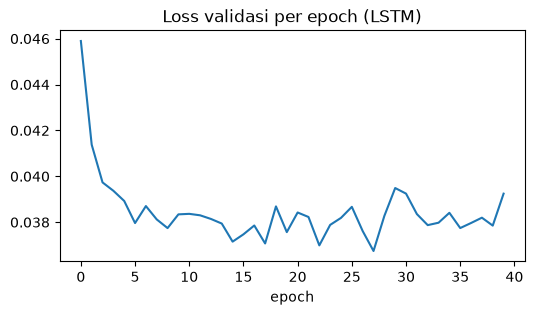

In [15]:
A = L.build_arrays(hourly, df)
assert (A["seq_last_label"] == A["issue"]).all(), "Sekuens observasi melewati waktu penerbitan!"
TR, VA = (np.where(A["split"] == s)[0] for s in ("train", "val"))
NORM = L.Normalizer().fit(A, TR); NORM.save(MOD / "lstm_normalizer.npz")
XS, XT = NORM.transform(A)
rows = A["row_index"]
def kc_to_rows(kc_days):
    return pd.Series(kc_days.ravel(), index=rows.ravel()).reindex(df.index).to_numpy()

if "lstm" not in BEST:
    import optuna
    optuna.logging.set_verbosity(optuna.logging.WARNING)
    vm, yv = VALM.to_numpy(), df["y_ghi"].to_numpy()[VALM.to_numpy()]
    def objective(trial):
        p = L.search_space(trial)
        net, _ = L.train(p, XS, XT, A["y"], A["w_train"], A["w_eval"], TR, VA, SEED)
        pred = M.finalize(kc_to_rows(L.predict(net, XS, XT)) * df["ghi_cs"].fillna(0).to_numpy(), df, KZ, True)
        return float(np.sqrt(np.nanmean((pred[vm] - yv) ** 2)))
    study = optuna.create_study(direction="minimize", sampler=optuna.samplers.TPESampler(seed=SEED))
    study.optimize(objective, n_trials=N_TRIALS["lstm"])
    BEST["lstm"] = study.best_params
    study.trials_dataframe().to_csv(RES / "optuna_lstm.csv", index=False)
    _ = bp.write_text(json.dumps(BEST, indent=2))

t0 = time.time()
NET, HIST = L.train(BEST["lstm"], XS, XT, A["y"], A["w_train"], A["w_eval"], TR, VA, SEED)
import torch; torch.save(NET.state_dict(), MOD / "lstm_best.pt")
raw = kc_to_rows(L.predict(NET, XS, XT)) * df["ghi_cs"].fillna(0).to_numpy()
P["raw_lstm"] = raw
P["pred_lstm"] = M.finalize(raw, df, KZ, do_clip=True)
print(f"LSTM dilatih {time.time() - t0:.0f} dtk, {len(HIST)} epoch")
plt.figure(figsize=(6, 3)); plt.plot(HIST); plt.title("Loss validasi per epoch (LSTM)"); plt.xlabel("epoch")
plt.savefig(FIG / "lstm_val_loss.png", dpi=150, bbox_inches="tight"); plt.show()

## 7. Simpan prediksi + cek identik dengan run sebelumnya

In [16]:
out = PROC / "predictions.parquet"
if out.exists():
    old = pd.read_parquet(out)
    common = [c for c in P.columns if c.startswith(("pred_", "abl__")) and c in old]
    diffs = {c: float(np.nanmax(np.abs(P[c].to_numpy() - old[c].to_numpy()))) for c in common}
    bad = {c: round(v, 4) for c, v in diffs.items() if v > 1e-3}
    print("Kolom dibandingkan:", len(common), "|", "✓ identik dengan run sebelumnya" if not bad else f"⚠ BERBEDA: {bad}")
    shutil.copy(out, PROC / "predictions_prev.parquet")
P.to_parquet(out)
print("Disimpan:", out.relative_to(ROOT), "|", len(P.columns), "kolom")

Kolom dibandingkan: 15 | ✓ identik dengan run sebelumnya
Disimpan: data\processed\predictions.parquet | 32 kolom
